In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
df=pd.read_csv("Dataset-Coginifiyz.csv",encoding='utf-8-sig')
df.head(1)

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314


In [5]:
df.columns = df.columns.str.replace("ï»¿", "", regex=False).str.strip()

In [6]:
d = df.copy()
d = d.drop(columns=["Rating color", "Rating text", "Restaurant ID",
                    "Restaurant Name", "Address", "Locality Verbose",
                    "Switch to order menu", "Currency"], errors="ignore")

In [7]:
d["Cuisines"] = d["Cuisines"].fillna("Unknown")
d["Cuisines"] = d["Cuisines"].str.split(",").str[0].str.strip()
d.isnull().sum().sum()

0

In [8]:
for c in ["Has Table booking", "Has Online delivery", "Is delivering now"]:
    d[c] = d[c].map({"Yes": 1, "No": 0})

d = d.drop(columns=["Locality"])   # bahut zyada columns banate hain
d = pd.get_dummies(d, columns=["City", "Cuisines"], drop_first=True)
d.shape

(9551, 269)

In [9]:
X = d.drop(columns="Aggregate rating")
y = d["Aggregate rating"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [10]:
models = {
    "Linear": LinearRegression(),
    "DecisionTree": DecisionTreeRegressor(max_depth=12, random_state=42),
    "RandomForest": RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    print(f"{name:13} MSE={mean_squared_error(y_test, p):.3f}  R2={r2_score(y_test, p):.3f}")

Linear        MSE=1.471  R2=0.354
DecisionTree  MSE=0.118  R2=0.948
RandomForest  MSE=0.086  R2=0.962


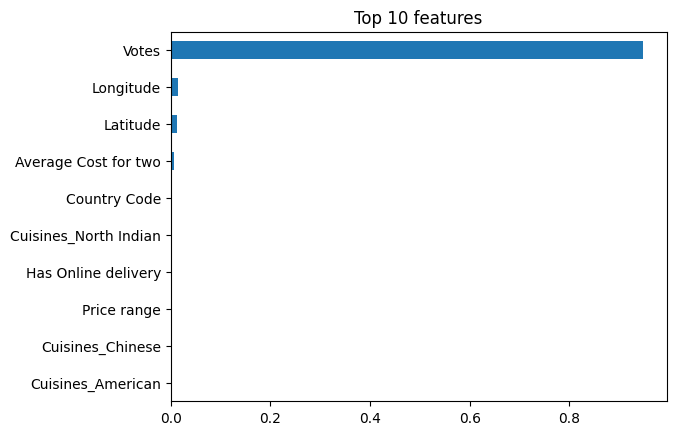

In [11]:
rf = models["RandomForest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.head(10).plot(kind="barh", title="Top 10 features").invert_yaxis()

In [12]:
sample = X_test.iloc[[0]]
print("Predicted:", rf.predict(sample)[0].round(2))
print("Actual   :", y_test.iloc[0])

Predicted: 3.33
Actual   : 2.1


In [13]:
def predict_rating(city, cuisine, votes, price_range, avg_cost,
                   table_booking=0, online_delivery=0, delivering_now=0,
                   country_code=1, longitude=0, latitude=0):
    row = pd.DataFrame(0, index=[0], columns=X.columns)  # sab zero se start

    # numeric columns
    row["Country Code"] = country_code
    row["Longitude"] = longitude
    row["Latitude"] = latitude
    row["Average Cost for two"] = avg_cost
    row["Price range"] = price_range
    row["Votes"] = votes
    row["Has Table booking"] = table_booking
    row["Has Online delivery"] = online_delivery
    row["Is delivering now"] = delivering_now

    # one-hot columns (agar city/cuisine training mein thi tabhi 1 hoga)
    for col in (f"City_{city}", f"Cuisines_{cuisine}"):
        if col in row.columns:
            row[col] = 1
        else:
            print(f"Note: '{col}' training data mein nahi tha, ignore kiya")

    return rf.predict(row)[0]

In [14]:
pred = predict_rating(city="New Delhi", cuisine="North Indian",
                      votes=300, price_range=2, avg_cost=800,
                      table_booking=1, online_delivery=1)
print(f"Predicted rating: {pred:.2f}")

Predicted rating: 4.12


In [15]:
import joblib
joblib.dump(rf, "task1_rating_model.joblib")

['task1_rating_model.joblib']